I0000 00:00:1794307869.388255      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794307885.929918      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow Version: 2.21.0
GPU Available: []
Dataset Path: /kaggle/input/datasets/alessiocorrado99/animals10/raw-img
Animal Classes: ['cane', 'cavallo', 'elefante', 'farfalla', 'gallina', 'gatto', 'mucca', 'pecora', 'ragno', 'scoiattolo']
Total Classes: 10


E0000 00:00:1794307890.109580      50 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


cane : 4863 images
cavallo : 2623 images
elefante : 1446 images
farfalla : 2112 images
gallina : 3098 images
gatto : 1668 images
mucca : 1866 images
pecora : 1820 images
ragno : 4821 images
scoiattolo : 1862 images
Found 26179 files belonging to 10 classes.
Using 20944 files for training.
Found 26179 files belonging to 10 classes.
Using 5235 files for validation.
Classes: ['cane', 'cavallo', 'elefante', 'farfalla', 'gallina', 'gatto', 'mucca', 'pecora', 'ragno', 'scoiattolo']


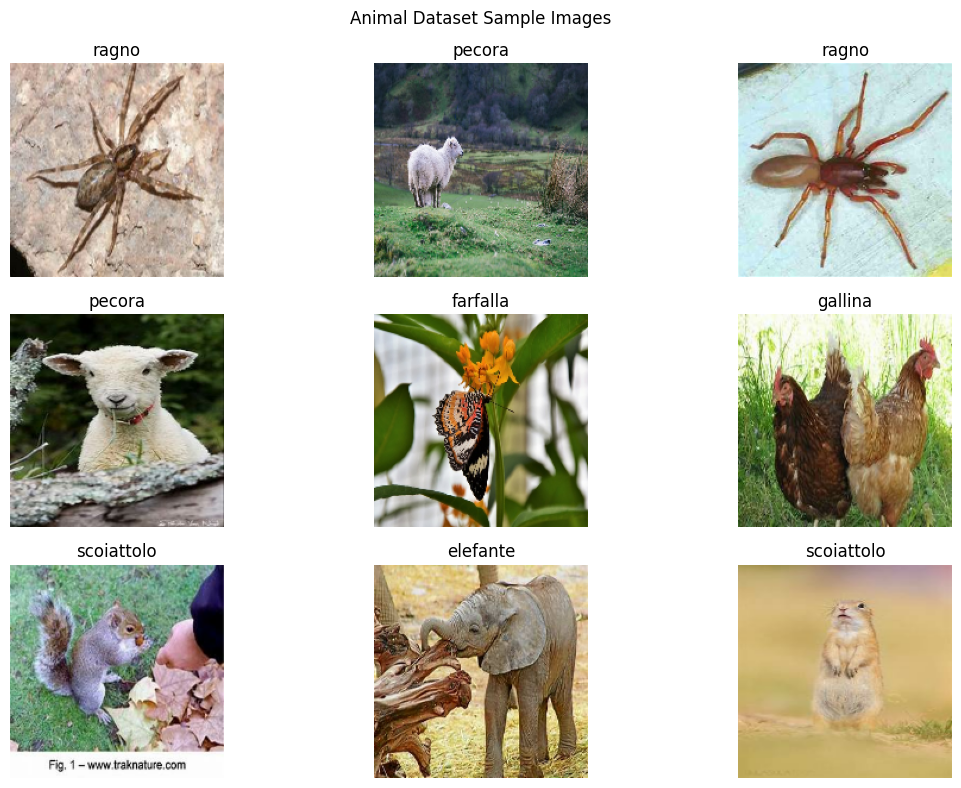

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 20736)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     5,308,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,699,658 (21.74 MB)

 Trainable params: 5,699,658 (21.74 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
 14/655 ━━━━━━━━━━━━━━━━━━━━ 14:48 1s/step - accuracy: 0.0943 - loss: 2.3365

In [ ]:

# ============================================================
# ANIMAL IMAGE CLASSIFICATION USING CNN
# Dataset: Animals-10 (Kaggle)
# Platform: Kaggle Notebook
# Framework: TensorFlow / Keras
# ============================================================

# CELL 1: IMPORT LIBRARIES

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))


# CELL 2: DATASET LOCATION

DATASET_PATH = "/kaggle/input/datasets/alessiocorrado99/animals10/raw-img"

if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(
        "Dataset not found. Add Animals-10 from Kaggle "
        "using Add Input."
    )

print("Dataset Path:", DATASET_PATH)

class_names = sorted([
    folder.name for folder in Path(DATASET_PATH).iterdir()
    if folder.is_dir()
])

print("Animal Classes:", class_names)
print("Total Classes:", len(class_names))

assert len(class_names) == 10, "Expected 10 animal classes."


# CELL 3: DATASET INFORMATION

for animal in class_names:
    folder = Path(DATASET_PATH) / animal
    count = len(list(folder.glob("*")))
    print(animal, ":", count, "images")


# CELL 4: LOAD DATASET

IMAGE_SIZE = (180, 180)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names

print("Classes:", class_names)


# CELL 5: DISPLAY SAMPLE IMAGES

plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

plt.suptitle("Animal Dataset Sample Images")
plt.tight_layout()
plt.show()


# CELL 6: OPTIMIZE DATASET

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)


# CELL 7: DATA AUGMENTATION

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])


# CELL 8: BUILD CNN MODEL

model = models.Sequential([

    layers.Input(shape=(180, 180, 3)),

    data_augmentation,

    layers.Rescaling(1./255),

    # First Convolution Block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Second Convolution Block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Third Convolution Block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Fourth Convolution Block
    layers.Conv2D(256, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Classification Layers
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(10, activation='softmax')
])

model.summary()


# CELL 9: COMPILE MODEL

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


# CELL 10: TRAIN MODEL

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

EPOCHS = 15

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)


# CELL 11: MODEL EVALUATION

loss, accuracy = model.evaluate(val_ds)

print("\nModel Evaluation")
print("-------------------------")
print("Validation Loss:", round(loss, 4))
print("Validation Accuracy:", round(accuracy * 100, 2), "%")


# CELL 12: ACCURACY GRAPH

plt.figure(figsize=(10, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("CNN Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# CELL 13: LOSS GRAPH

plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("CNN Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


# CELL 14: CLASSIFICATION REPORT

y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))


# CELL 15: CONFUSION MATRIX

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Animal Classification Confusion Matrix")
plt.xlabel("Predicted Animal")
plt.ylabel("Actual Animal")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


# CELL 16: PREDICT SAMPLE ANIMAL IMAGE

for images, labels in val_ds.take(1):

    predictions = model.predict(images, verbose=0)

    plt.figure(figsize=(12, 8))

    for i in range(min(9, len(images))):

        predicted_index = np.argmax(predictions[i])
        confidence = predictions[i][predicted_index] * 100

        actual_name = class_names[labels[i].numpy()]
        predicted_name = class_names[predicted_index]

        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(
            f"Actual: {actual_name}\n"
            f"Predicted: {predicted_name}\n"
            f"Confidence: {confidence:.2f}%"
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()


# CELL 17: PREDICT A CUSTOM IMAGE

def predict_animal(image_path):

    img = tf.keras.utils.load_img(
        image_path,
        target_size=IMAGE_SIZE
    )

    img_array = tf.keras.utils.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array, verbose=0)

    predicted_index = np.argmax(prediction[0])

    animal_name = class_names[predicted_index]
    confidence = prediction[0][predicted_index] * 100

    plt.imshow(img)
    plt.axis("off")
    plt.title(
        f"Predicted: {animal_name}\n"
        f"Confidence: {confidence:.2f}%"
    )
    plt.show()

    print("Predicted Animal:", animal_name)
    print("Confidence:", round(confidence, 2), "%")


# Example:
# predict_animal("/kaggle/input/your-dataset/dog.jpg")


# CELL 18: SAVE TRAINED MODEL

model.save("/kaggle/working/animal_cnn_model.keras")

print("Model saved successfully!")
print("Saved File: /kaggle/working/animal_cnn_model.keras")


# CELL 19: FINAL RESULT

print("\n================================")
print("ANIMAL IMAGE CLASSIFICATION")
print("================================")
print("Algorithm: Convolutional Neural Network")
print("Dataset: Animals-10")
print("Number of Classes:", len(class_names))
print("Validation Accuracy:", round(accuracy * 100, 2), "%")
print("Model Training Completed Successfully!")
